# Task 1: الداتا قبل الذكاء الأصطناعي

# 1. Garbage In, Garbage Out

يعني إذا كانت البيانات فيها أخطاء، فالنتائج اللي يعطينا إياها الذكاء الاصطناعي ممكن تكون خاطئة أيضًا

مثال: لو دربنا موديل على أسعار سيارات فيها أخطاء، ممكن يتوقع أسعار غير صحيحة

# 2. مشاكل البيانات

| المشكلة | مكانها | النوع | القرار | السبب |
|---|---|---|---|---|
| اختلاف كتابة الرياض | city | Inconsistency | توحيد الاسم | حتى تكون بنفس الشكل |
| العمر مفقود | age في الصف الثالث | Null | تعويضه بالوسيط | حتى ما تكون فيه قيمة فارغة |
| العمر 250 | age في الصف الرابع | Outlier | مراجعة القيمة | لأن العمر غير منطقي |
| تكرار الطلب 1002 | order_id | Duplicate | حذف التكرار | لأنه نفس الطلب |
| المبلغ مكتوب بالكلمات | amount في الصف السادس | Wrong type | تحويله إلى رقم بعد تصحيحه | حتى نقدر نستخدمه في الحسابات |

# 3. Features و Target

المشكلة: معرفة مدة الانتظار في عيادة بالرياض.

**Target:** مدة الانتظار.

**Features:**
1. عدد المرضى
2. عدد الأطباء
3. وقت الموعد
4. يوم الأسبوع
5. عدد المواعيد

**عمود لن أستخدمه:** اسم المريض، لأنه ما يساعد في توقع مدة الانتظار

## 4. لماذا نجهز البيانات قبل بناء الموديل؟

لأن البيانات ممكن يكون فيها أخطاء أو قيم ناقصة أو مكررة, لذلك لازم ننظفها ونرتبها حتى نحصل على نتائج أفضل

# Task 2 بيئة العمل واول array:

In [4]:
# 1. استيراد المكتبات

import numpy as np
import pandas as pd

print(np.__version__)
print(pd.__version__)

2.4.6
2.2.3


# 2. لقطة شاشة الملفات المرفوعة من Kaggle

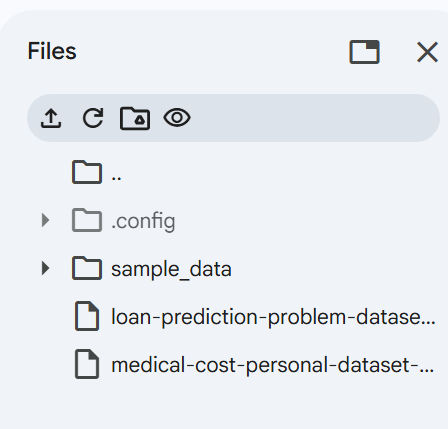

# 3. توقع النتائج قبل تشغيل الكود

prices_list 2 : ستتكرر عناصر القائمة مرتين

prices 2: ستتضاعف كل قيمة

prices_list + [1, 1, 1]: ستُضاف القيم لبعضها حسب موقعها

prices + np.array([1, 1, 1]): ستُضاف 1 لكل عنصر في المصفوفة

In [12]:
prices_list = [25, 18, 32]
prices = np.array(prices_list)

print(prices_list * 2)
print(prices * 2)

print(prices_list + [1, 1, 1])
print(prices + np.array([1, 1, 1]))

[25, 18, 32, 25, 18, 32]
[50 36 64]
[25, 18, 32, 1, 1, 1]
[26 19 33]


# الاختلاف بين التوقع والنتيجة

كانت أغلب توقعاتي صحيحة، لكن النتيجة الثالثة كانت مختلفة توقعت أن القيم تُجمع مع بعضها
لكن اكتشفت أن القوائم يتم دمجها

 بينما في NumPy

يتم جمع كل عنصر مع العنصر المقابل له


# الفرق بين List و Array

من خلال الكود لاحظت ان الـ "List"

عند استخدام (+)
تدمج قائمتين مع بعض.

و "Array" تجمع كل عنصر مع العنصر المقابل له.

In [15]:
# خصائص array

print("Shape:", prices.shape)
print("Dimensions:", prices.ndim)
print("Size:", prices.size)
print("Data type:", prices.dtype)

Shape: (3,)
Dimensions: 1
Size: 3
Data type: int64


In [14]:
# dtype:

numbers = np.array([1, 2.5, 3])
words = np.array([1, "2", 3])

print(numbers)
print(numbers.dtype)

print(words)
print(words.dtype)

[1.  2.5 3. ]
float64
['1' '2' '3']
<U21


لاحظت أن NumPy

 حوّلت الأرقام الصحيحة إلى أرقام عشرية عند وجود رقم عشري، وفي المصفوفة الثانية حوّلت الأرقام إلى نصوص بسبب وجود قيمة نصية.

 لأن عناصر array
  تكون من نفس النوع.

# Task3: أسبوع كافيه في الرياض

In [16]:
# ادخال البيانات

days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

sales = np.array([1240, 980, 1105, 1320, 1875, 2410, 2150])

In [17]:
# حساب المبيعات

print("Total:", np.sum(sales))
print("Mean:", np.mean(sales))
print("Median:", np.median(sales))
print("Max:", np.max(sales))
print("Min:", np.min(sales))
print("Std:", np.std(sales))

Total: 11080
Mean: 1582.857142857143
Median: 1320.0
Max: 2410
Min: 980
Std: 516.8023741020846


In [18]:
# افضل واسوء يوم

best = np.argmax(sales)
worst = np.argmin(sales)

print("Best day:", days[best], sales[best])
print("Worst day:", days[worst], sales[worst])

Best day: Fri 2410
Worst day: Mon 980


In [19]:
# Boolen mask

mask = sales > np.mean(sales)

print(mask)
print("Days above average:", np.sum(mask))
print("Their sales:", sales[mask])

[False False False False  True  True  True]
Days above average: 3
Their sales: [1875 2410 2150]


In [20]:
# مبيعات نهاية الاسبوع

weekend = sales[5:7]

print("Weekend sales:", weekend)
print("Weekend total:", np.sum(weekend))
print("Weekend share:", np.sum(weekend) / np.sum(sales) * 100)

Weekend sales: [2410 2150]
Weekend total: 4560
Weekend share: 41.15523465703971


In [21]:
# الضريبة وهدف الاسبوع القادم

after_tax = sales * 1.15
next_week = sales * 1.10

print("Sales after tax:", after_tax)
print("Next week target:", next_week)

Sales after tax: [1426.   1127.   1270.75 1518.   2156.25 2771.5  2472.5 ]
Next week target: [1364.  1078.  1215.5 1452.  2062.5 2651.  2365. ]


In [22]:
# التغير بين الأيام باستخدام np.diff

change = np.diff(sales)

print("Daily changes:", change)

biggest = np.argmax(change)

print("Biggest increase:", change[biggest])
print("Between:", days[biggest], "and", days[biggest + 1])

Daily changes: [-260  125  215  555  535 -260]
Biggest increase: 555
Between: Wed and Thu


# سؤال:

لو سأل صاحب الكافية
**كم ابيع في يوم عادي؟**

اعطيه المتوسط او الوسيط ولماذا؟

أعطيه الوسيط وهو 1320 ريال، لأن المتوسط 1582.86 ريال تأثر بارتفاع المبيعات يوم الجمعة والسبت، بينما الوسيط يعطينا فكرة أفضل عن مبيعات اليوم العادي.

# Task4: ثلاثة فروع في جدول واحد

In [24]:
# البيانات

branches = ["Riyadh", "Jeddah", "Dammam"]
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

sales = np.array([
    [1240, 980, 1105, 1320, 1875, 2410, 2150],
    [910, 870, 990, 1010, 1430, 1980, 2240],
    [640, 720, 680, 750, 990, 1210, 1080]
])

In [25]:
print(sales.shape)

(3, 7)


الرقم 3 يمثل عدد الفروع، والرقم 7 يمثل عدد أيام الأسبوع

In [26]:
# استخراج المبيعات

print("Jeddah Thursday:", sales[1, 4])

print("Dammam sales:", sales[2, :])

print("Friday sales:", sales[:, 5])

print("Friday and Saturday:")
print(sales[:, 5:7])

Jeddah Thursday: 1430
Dammam sales: [ 640  720  680  750  990 1210 1080]
Friday sales: [2410 1980 1210]
Friday and Saturday:
[[2410 2150]
 [1980 2240]
 [1210 1080]]


In [27]:
# مجموع كل فرع وكل يوم

branch_total = np.sum(sales, axis=1)
day_total = np.sum(sales, axis=0)

print("Branch totals:", branch_total)
print("Day totals:", day_total)

Branch totals: [11080  9430  6070]
Day totals: [2790 2570 2775 3080 4295 5600 5470]


axis=1 يحسب مجموع مبيعات كل فرع،

و axis=0 يحسب مجموع مبيعات كل يوم

In [28]:
# افضل فرع وافضل يوم

best_branch = np.argmax(branch_total)
best_day = np.argmax(day_total)

print("Best branch:", branches[best_branch])
print("Best day:", days[best_day])

print("Branch percentages:", branch_total / np.sum(sales) * 100)

Best branch: Riyadh
Best day: Fri
Branch percentages: [41.6854778  35.47780286 22.83671934]


In [29]:
# اعلى مبيعات في خلية واحدة

max_index = np.argmax(sales)

row = max_index // 7
col = max_index % 7

print("Highest sales:", sales[row, col])
print("Branch:", branches[row])
print("Day:", days[col])

Highest sales: 2410
Branch: Riyadh
Day: Fri


# سؤال : اي فرع اقترح اغلاقة في يوم الاحد؟

أقترح إغلاق فرع الدمام يوم الأحد لأن مبيعاته كانت الأقل بمبلغ 640 ريال، مقارنة بالرياض 1240 ريال وجدة 910 ريال